In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad, solve_bvp
from scipy.interpolate import CubicSpline
from numba import jit, njit, prange

try:
    plt.style.use("emilie_style.mplstyle")
    colors = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
except (OSError, FileNotFoundError):
    print("emilie_style.mplstyle not found - falling back to matplotlib defaults")

In [2]:
from Functions import compute_for_sigmoidal

# Functions

In [3]:
# ________________________________________________________________
# Two-state model Backward Kolmogorov equations solver
# _______________________________________________________________

def compute_for_two_state(
    r_target,
    rf,
    rn,
    A,
    b,
    D0,
    Dn,
    lam=1.0,
    gamma=0.1,
    activation_outside=1,
    ndim=3,
    N=4000,
    tol=1e-4,
    max_nodes=20000,
):
    """
    Computes both T_A(r) and T_I(r) for the two-state model.

    Active state:
        -1 = LT_A - gamma * (T_A - T_I)
        T_A(r_target) = 0
        T_A'(rn) = 0

    Inactive state:
        -1 = LT_I - lambda(r) * (T_I - T_A)
        T_I'(r_target) = 0
        T_I'(rn) = 0

    where L is the generator of the diffusion process:
        Lf = D(r) f'' + mu(r) f'

    Parameters
    ----------
    r_target : float
        Target radius.
    rf : float
        Droplet radius (where the sigmoidal functions are centered).
    rn : float
        Outer reflecting boundary radius.
    A : float
        Amplitude of the sigmoidal function for the potential U(r).
    b : float
        Steepness of the sigmoidal function for the potential U(r).
    D0 : float
        Diffusion coefficient inside the droplet (r < rf).
    Dn : float
        Diffusion coefficient outside the droplet (r > rf).
    lam : float, optional
        Maximum activation rate (default 1.0).
    gamma : float, optional
        Deactivation rate (default 0.1).
    activation_outside : int, optional
        If 1, activation occurs outside the droplet; if 0, inside (default 1).
    ndim : int, optional
        Spatial dimension (default 3).
    N : int, optional
        Number of spatial grid points.
    tol : float, optional
        Tolerance for the solution (default 1e-4).
    max_nodes : int, optional
        Maximum number of nodes for the solver (default 20000).


    Returns
    -------
    TA_func : callable
        Interpolating function for T_A(r).
    TI_func : callable
        Interpolating function for T_I(r).
    out : dict
        Diagnostics and raw arrays.
    """

    # ------------------------------------------------------------
    # Define U(r), D(r), and related functions
    # ------------------------------------------------------------

    def sig(rr):
        """1/(1+exp(-b(r-rf))): 0 deep inside the condensate, 1 well outside."""
        return 1.0 / (1.0 + np.exp(-b * (rr - rf)))

    def dsig(rr):
        e = np.exp(-b * (rr - rf))
        return b * e / (1.0 + e) ** 2
    
    def D_func(rr):
        return D0 + (Dn - D0) * sig(rr)

    def mu_func(rr):
        s  = sig(rr)
        ds = dsig(rr)
        D  = D0 + (Dn - D0) * s
        return (ndim - 1) * D / rr + (Dn - D0) * ds - D * A * ds

    def lambda_func(rr):
        """Activation rate. Control whether activation occurs inside or outside the condensate."""
        s = sig(rr)
        if activation_outside == 1:
            return lam * s
        return lam * (1.0 - s)


    # ============================================================
    # BVP system
    # ============================================================
    # Unknown vector:
    # y[0] = T_A
    # y[1] = T_A'
    # y[2] = T_I
    # y[3] = T_I'

    def ode_system(r, y):
        TA, dTA, TI, dTI = y

        D = D_func(r)
        mu = mu_func(r)
        lam = lambda_func(r)

        # From:
        # -1 = mu dTA + D d2TA - gamma (TA - TI)
        # -1 = mu dTI + D d2TI - lambda(r) (TI - TA)
        #
        # Therefore:
        # d2TA = [ -1 - mu dTA + gamma (TA - TI) ] / D
        # d2TI = [ -1 - mu dTI + lambda(r) (TI - TA) ] / D

        ddTA = (-1.0 - mu * dTA + gamma * (TA - TI)) / D
        ddTI = (-1.0 - mu * dTI + lam   * (TI - TA)) / D

        return np.vstack((dTA, ddTA, dTI, ddTI))

    def bc(ya, yb):
        """
        Boundary conditions:
        T_A(r_target)   = 0
        T_A'(rn)  = 0
        T_I'(r_target)  = 0
        T_I'(rn)  = 0
        """
        return np.array([
            ya[0],      # T_A(r_target) = 0
            yb[1],      # T_A'(rn) = 0
            ya[3],      # T_I'(r_target) = 0
            yb[3],      # T_I'(rn) = 0
        ])
    
    # ============================================================
    # Initial mesh and guess
    # ============================================================

    r_mesh = np.linspace(r_target, rn, N)

    # A simple initial guess:
    L = rn - r_target
    x = (r_mesh - r_target) / L

    TA_guess = L**2 * (2*x - x**2)   # TA(r_target)=0, TA'(rn)=0
    dTA_guess = 2*L*(1 - x)

    TI_guess = np.full_like(r_mesh, L**2)   # constant => derivative zero at both ends
    dTI_guess = np.zeros_like(r_mesh)

    y_guess = np.vstack((TA_guess, dTA_guess, TI_guess, dTI_guess))

    # ============================================================
    # Solve the boundary value problem
    # ============================================================

    sol = solve_bvp(ode_system, bc, r_mesh, y_guess, tol=tol, max_nodes=max_nodes)

    if not sol.success:
        raise RuntimeError(f"BVP solver failed: {sol.message}")
   
    # ============================================================
    # Evaluate and interpolate solutions
    # ============================================================
        
    r_eval = np.linspace(r_target, rn, 1000)
    TA_sol = sol.sol(r_eval)[0]
    TI_sol = sol.sol(r_eval)[2]

    TA_spline = CubicSpline(r_eval, TA_sol, bc_type="natural", extrapolate=False)
    TI_spline = CubicSpline(r_eval, TI_sol, bc_type="natural", extrapolate=False)
    
    def TA_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TA_spline(r)

    def TI_func(r):
        r = np.asarray(r)
        if np.any((r < r_target) | (r > rn)):
            raise ValueError("r must lie within [r_target, rn].")
        return TI_spline(r)

    out = {
        "r_grid": r_eval,
        "TA_values": TA_sol,
        "TI_values": TI_sol,
        "TA_rn": float(TA_spline(rn)),
        "TI_rn": float(TI_spline(rn)),
        "drift": mu_func(r_eval),
        "lambda_values": lambda_func(r_eval),
    }

    return TA_func, TI_func, out

In [4]:
# ──────────────────────────────────────────────────────────────────────────────
# Field helpers
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True, inline="always")
def _sig(r, b, rf):
    """1/(1+exp(-b(r-rf))): 0 deep inside the condensate, 1 well outside."""
    return 1.0 / (1.0 + np.exp(-b * (r - rf)))


@njit(cache=True, inline="always")
def _dsig(r, b, rf):
    e = np.exp(-b * (r - rf))
    return b * e / (1.0 + e) ** 2


@njit(cache=True)
def _D_func(r, b, rf, D0, Dn):
    return D0 + (Dn - D0) * _sig(r, b, rf)


@njit(cache=True)
def _mu_func(r, b, rf, A, D0, Dn, ndim):
    s  = _sig(r, b, rf)
    ds = _dsig(r, b, rf)
    D  = D0 + (Dn - D0) * s
    return (ndim - 1) * D / r + (Dn - D0) * ds - D * A * ds


@njit(cache=True)
def _lambda_func(r, b, rf, lam, activation_outside):
    """Activation rate. Control whether activation occurs inside or outside the condensate."""
    s = _sig(r, b, rf)
    if activation_outside == 1:
        return lam * s
    return lam * (1.0 - s)


@njit(cache=True)
def _t_step(r, dt_max, alpha, b, rf, A, D0, Dn, lam, gamma):
    """Adaptive step: potential gradient, interface width, and chemical rates.
    alpha is a tunable parameter that controls the sensitivity of the time step to the potential gradient.
    large alpha -> smaller time steps in regions of high potential gradient."""
    dt = dt_max / (1.0 + alpha * abs(A) * _dsig(r, b, rf))
    Dmax = D0 if D0 > Dn else Dn
    if b > 0.0:
        dt = min(dt, 0.1 / (2.0 * Dmax * b * b))      # sqrt(2 D dt) <= 0.32 / b
    rmax = lam if lam > gamma else gamma
    if rmax > 0.0:
        dt = min(dt, 0.05 / rmax)                      # rate * dt <= 0.05
    return dt


# ──────────────────────────────────────────────────────────────────────────────
# First-passage mode
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True, parallel=True)
def _run_trajectories(r0, state0, r_target, rf, rn, A, b, D0, Dn, lam, gamma,
                      dt_max, alpha, ndim, seeds, max_steps,
                      activation_outside, use_bridge):
    n = seeds.shape[0]
    fpt = np.full(n, np.nan)

    for traj in prange(n):
        np.random.seed(seeds[traj])          # reproducible regardless of thread assignment
        r, state, t = r0, state0, 0.0

        for _ in range(max_steps):
            delta_t = _t_step(r, dt_max, alpha, b, rf, A, D0, Dn, lam, gamma)

            if state == 0:
                rate = _lambda_func(r, b, rf, lam, activation_outside)
            else:
                rate = gamma
            if rate > 0.0 and np.random.rand() < 1.0 - math.exp(-rate * delta_t):
                state = 1 - state

            D  = _D_func(r, b, rf, D0, Dn)
            mu = _mu_func(r, b, rf, A, D0, Dn, ndim)
            r_new = r + mu * delta_t + math.sqrt(2.0 * D * delta_t) * np.random.standard_normal()

            while r_new > rn:
                r_new = 2.0 * rn - r_new
            t += delta_t

            if state == 1:
                if r_new <= r_target:
                    frac = (r - r_target) / (r - r_new)
                    fpt[traj] = (t - delta_t) + frac * delta_t
                    break
                if use_bridge == 1:
                    # P(path touched r_target | both endpoints above it)
                    p_hit = math.exp(-(r - r_target) * (r_new - r_target) / (D * delta_t))
                    if np.random.rand() < p_hit:
                        fpt[traj] = t - 0.5 * delta_t
                        break
            else:
                if r_new <= r_target:
                    r_new = 2.0 * r_target - r_new

            r = r_new

    return fpt


def simulate_two_state_mfpt(r0, state0, r_target, rf, rn, A, b, D0, Dn,
                            lam=0.01, gamma=0.01, dt_max=1e-4, alpha=0.05,
                            ndim=3, n_trajectories=1000, max_steps=10_000_000,
                            seed=None, activation_outside=True, use_bridge=True):
    """
    MFPT to an inner target that absorbs only particles in the active state.

    activation_outside : True  -> activation only outside the condensate 
                         False -> activation only inside the condensate
    use_bridge         : Brownian-bridge absorption; set False only to reproduce
                         the uncorrected result.

    If n_truncated > 0 the reported mean is a censored estimate biased LOW, because
    the dropped trajectories are the slow ones.  Raise max_steps until it is zero.
    """
    rng = np.random.default_rng(seed)
    seeds = rng.integers(1, 2**31 - 1, n_trajectories).astype(np.int64)

    fpt = _run_trajectories(r0, state0, r_target, rf, rn, A, b, D0, Dn, lam, gamma,
                            dt_max, alpha, ndim, seeds, max_steps,
                            1 if activation_outside else 0, 1 if use_bridge else 0)

    completed   = fpt[~np.isnan(fpt)]
    n_completed = len(completed)
    n_truncated = n_trajectories - n_completed
    if n_truncated:
        import warnings
        warnings.warn(f"{n_truncated}/{n_trajectories} trajectories hit max_steps; "
                      "mean_fpt is censored and biased low.", RuntimeWarning)

    return {
        "mean_fpt"   : float(np.mean(completed))                       if n_completed else np.nan,
        "std_fpt"    : float(np.std(completed))                        if n_completed else np.nan,
        "stderr_fpt" : float(np.std(completed) / np.sqrt(n_completed)) if n_completed > 1 else np.nan,
        "fpt_samples": completed,
        "n_completed": n_completed,
        "n_truncated": n_truncated,
    }

In [5]:
# ──────────────────────────────────────────────────────────────────────────────
# Occupancy mode - the observable the mean-field model actually predicts
# ──────────────────────────────────────────────────────────────────────────────

@njit(cache=True, parallel=True)
def _run_occupancy(r_min, r_split, rf, rn, A, b, D0, Dn, lambda0, gamma,
                   dt_max, alpha, ndim, seeds, t_total, t_burn, activation_outside):
    n = seeds.shape[0]
    acc = np.zeros((n, 4))                    # p_in_A, p_in_N, p_out_A, p_out_N

    for traj in prange(n):
        np.random.seed(seeds[traj])
        r, state, t = 0.5 * (rf + rn), 0, 0.0

        while t < t_total:
            delta_t = _t_step(r, dt_max, alpha, b, rf, A, D0, Dn, lambda0, gamma)

            if t >= t_burn:
                acc[traj, (0 if r < r_split else 2) + (0 if state == 1 else 1)] += delta_t

            if state == 0:
                rate = _lambda_func(r, b, rf, lambda0, activation_outside)
            else:
                rate = gamma
            if rate > 0.0 and np.random.rand() < 1.0 - math.exp(-rate * delta_t):
                state = 1 - state

            D  = _D_func(r, b, rf, D0, Dn)
            mu = _mu_func(r, b, rf, A, D0, Dn, ndim)
            r_new = r + mu * delta_t + math.sqrt(2.0 * D * delta_t) * np.random.standard_normal()

            while r_new > rn:
                r_new = 2.0 * rn - r_new
            while r_new < r_min:
                r_new = 2.0 * r_min - r_new

            r, t = r_new, t + delta_t

    return acc


def simulate_occupancies(rf, rn, A, b, D0, Dn, lambda0, gamma, r_min=None, r_split=None,
                         dt_max=1e-4, alpha=0.05, ndim=3, n_trajectories=200,
                         t_total=200.0, t_burn=20.0, seed=0, activation_outside=True):
    """
    Closed system, no absorbing target: steady-state occupancy of the four states.

    Returns the four occupancies with standard errors, plus the local active
    fractions alpha_in, alpha_out.  The exact relation
        alpha_in / alpha_out = k_- / (k_- + lambda_-)
    inverts to a direct measurement of the effective escape rate,
        k_- = lambda_- * ratio / (1 - ratio),
    which is how to calibrate the interfacial width delta in kappa_- = S D /(V_in delta).

    IMPORTANT: that inversion assumes activation is strictly zero inside, which the
    smooth sigmoid only satisfies when b*rf >> 1.  At b*rf ~ 5 the shoulder where
    lambda(r) > 0 covers most of the condensate by volume (the radial density goes
    as r^2 and the interior potential is flat, so particles pile up at r ~ rf) and
    the inferred k_- is badly contaminated.  Use b*rf >~ 50, and check convergence
    in b before trusting a delta.  Conditioning also requires k_- within an order of
    magnitude of lambda_-; otherwise the ratio sits at 1 and k_- is unidentifiable.
    """
    
    if r_min is None:
        r_min = 0.1 * rf
    if r_split is None:
        r_split = rf

    seeds = np.random.default_rng(seed).integers(1, 2**31 - 1, n_trajectories).astype(np.int64)
    acc = _run_occupancy(r_min, r_split, rf, rn, A, b, D0, Dn, lambda0, gamma,
                         dt_max, alpha, ndim, seeds, t_total, t_burn,
                         1 if activation_outside else 0)

    frac = acc / acc.sum(axis=1, keepdims=True)
    m    = frac.mean(axis=0)
    err  = frac.std(axis=0) / np.sqrt(n_trajectories)

    alpha_in  = m[0] / (m[0] + m[1])
    alpha_out = m[2] / (m[2] + m[3])
    ratio     = alpha_in / alpha_out
    k_minus   = gamma * ratio / (1.0 - ratio) if ratio < 1.0 else np.inf
    delta_inferred = (Dn / (4.0 * np.pi * rf**2)) / k_minus if k_minus > 0.0 else np.inf

    return {
        "p_in_A": m[0], "p_in_N": m[1], "p_out_A": m[2], "p_out_N": m[3], "stderr": err,
        "p_A": m[0] + m[2], "p_out": m[2] + m[3],
        "alpha_in": alpha_in, "alpha_out": alpha_out,
        "alpha_ratio": ratio, "k_minus_inferred": k_minus,
        "delta_inferred": delta_inferred,
    }

# Debug simulation algorithm with no switching

Compare to MFPT calculated for sigmoidal potential with constant diffusion without switching

In [6]:
# System parameters for the two-state model
rt_ = 0.01
rn_ = 0.5
D0_ = 1.0
Dn_ = 1.0
A_ = 5.0
b_ = 1000.0
ndim_ = 3

# Switching for the two-state model (set to zero for no switching)
lam, gamma = 0.0, 0.0
activation_outside = 1  # Activation occurs outside the droplet

# Simulation parameters
dt_max = 1e-3
alpha = 0.1
n_trajectories = 500
max_steps = 1_000_000_000

debug = False 
rf_debug = np.linspace(0.05, 0.15, 10)
mfpt_debug = np.zeros_like(rf_debug)

if debug:
    for i, rf in enumerate(rf_debug):
        print(f"Running simulation for rf = {rf:.3f}...")
        result = simulate_two_state_mfpt(
                r0=rn_, state0=1, r_target=rt_, rf=rf, rn=rn_,
                A=A_, b=b_, D0=D0_, Dn=Dn_,
                lam=lam, gamma=gamma, activation_outside=activation_outside,           
                dt_max=dt_max, alpha=alpha, 
                ndim=ndim_, n_trajectories=n_trajectories, max_steps=max_steps
                )
        mfpt_debug[i] = result['mean_fpt']

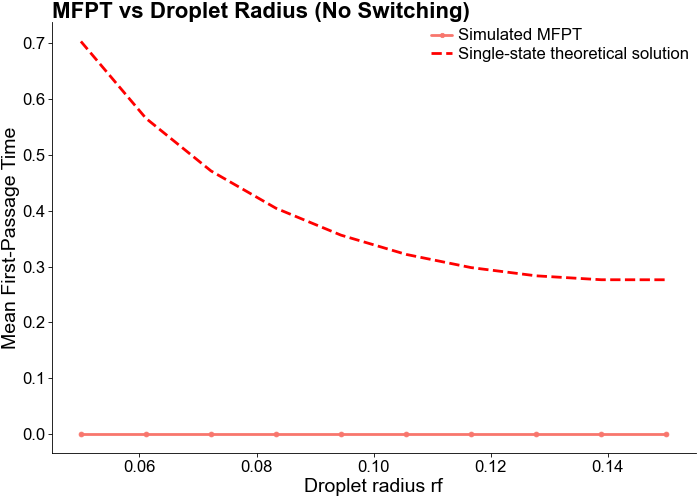

In [7]:
theoretical_mfpt = np.zeros_like(rf_debug)
for i, rf in enumerate(rf_debug):
    func, _ = compute_for_sigmoidal(rt_, rf, rn_, A_, b_, D0_, Dn_, ndim=ndim_, N=400)
    theoretical_mfpt[i] = func(rn_)

plt.figure()
plt.plot(rf_debug, mfpt_debug, 'o-', label='Simulated MFPT')
plt.plot(rf_debug, theoretical_mfpt, 'r--', label='Single-state theoretical solution')
plt.xlabel('Droplet radius rf')
plt.ylabel('Mean First-Passage Time')
plt.title('MFPT vs Droplet Radius (No Switching)')
plt.legend();

# Simulation and theory including switching

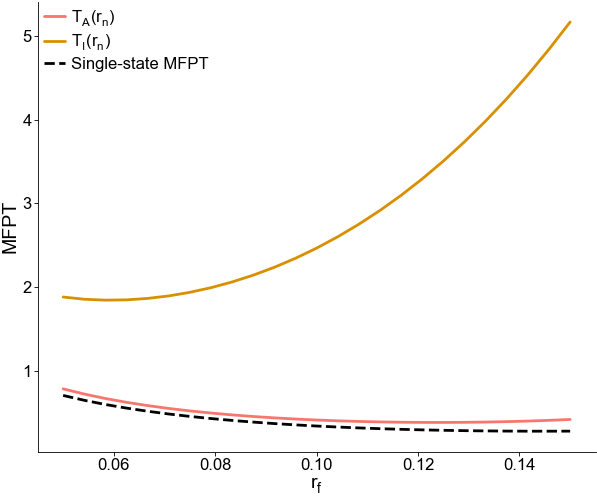

In [16]:
# Set range of rf values to explore
rf_vals = np.linspace(0.05, 0.15, 25)

# Initialize arrays to store results
T_A = np.zeros(len(rf_vals))
T_I = np.zeros(len(rf_vals))
T_single = np.zeros(len(rf_vals))

# Switching parameters for the two-state model
lam, gamma = 1.0, 0.1
activation_outside = 1  # Activation occurs outside the droplet

for i, rf in enumerate(rf_vals):
    TA_func, TI_func, out = compute_for_two_state(
        r_target=rt_,
        rf=rf,
        rn=rn_,
        A=A_,
        b=b_,
        D0=D0_,
        Dn=Dn_,
        lam=lam,
        gamma=gamma,
        activation_outside=activation_outside,
        ndim=ndim_,
        N=300,
        tol=1e-6,
        max_nodes=20000,
    )
    T_A[i] = out["TA_rn"]
    T_I[i] = out["TI_rn"]
    T_single[i] = compute_for_sigmoidal(rt_, rf, rn_, A_, b_, D0_, Dn_, ndim=ndim_, N=300)[0](rn_)

# Plot the simulation results with error bars
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(rf_vals, T_A, label=r'$T_A(r_n)$')
ax.plot(rf_vals, T_I, label=r'$T_I(r_n)$')
ax.plot(rf_vals, T_single, 'k--', label='Single-state MFPT')
ax.set_xlabel(r'$r_f$')
ax.set_ylabel('MFPT')
ax.legend();

Running simulations for rf = 0.100 (ratio = 0.10)...
Running simulations for rf = 0.143 (ratio = 0.14)...
Running simulations for rf = 0.186 (ratio = 0.19)...
Running simulations for rf = 0.229 (ratio = 0.23)...
Running simulations for rf = 0.271 (ratio = 0.27)...
Running simulations for rf = 0.314 (ratio = 0.31)...
Running simulations for rf = 0.357 (ratio = 0.36)...
Running simulations for rf = 0.400 (ratio = 0.40)...


/var/folders/kp/rpw6x9gx71ncgf2hj3y5qc080000gn/T/ipykernel_18206/3170141863.py:89: RuntimeWarning: overflow encountered in square
  return b * e / (1.0 + e) ** 2
/Users/cpr181/Desktop/GitHub/MFPT_Minimization/Functions.py:185: RuntimeWarning: overflow encountered in scalar power
  return e / (1.0 + e)**2


Running simulations for rf = 0.443 (ratio = 0.44)...
Running simulations for rf = 0.486 (ratio = 0.49)...
Running simulations for rf = 0.529 (ratio = 0.53)...
Running simulations for rf = 0.571 (ratio = 0.57)...
Running simulations for rf = 0.614 (ratio = 0.61)...
Running simulations for rf = 0.657 (ratio = 0.66)...
Running simulations for rf = 0.700 (ratio = 0.70)...


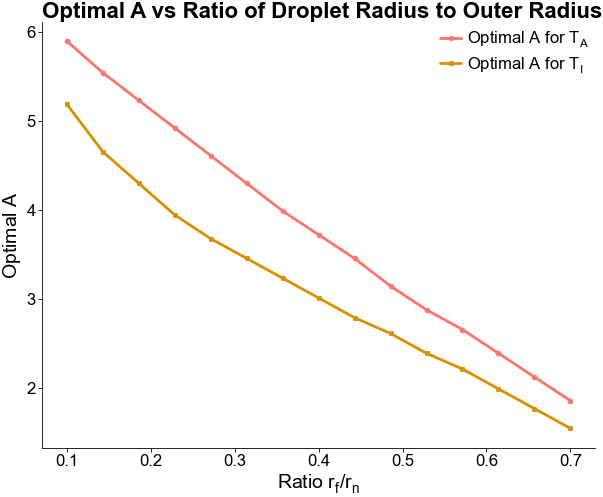

In [ ]:
# investigate the optimal A for a range of ratios between the outer and inner radii, with fixed rn

# Set range of ratios to explore
r_ratios_inner_to_outer = np.linspace(0.1, 0.7, 15)  # Varying the ratio of rn/rf
A_vals = np.linspace(1.5, 5.9, 100)  # A values to explore

# Initialize arrays to store results
results_A = []
results_I = []

# System parameters for the two-state model
rn = 1.0
D = 1.0
ndim_ = 3

# Switching parameters for the two-state model
lam, gamma = 1.0, 0.1
activation_outside = 1  # Activation occurs outside the droplet

for ratio in r_ratios_inner_to_outer:
    rf = rn * ratio
    
    T_A = np.zeros(len(A_vals))
    T_I = np.zeros(len(A_vals))
    T_single = np.zeros(len(A_vals))
    print(f"Running simulations for rf = {rf:.3f} (ratio = {ratio:.2f})...")

    for i, A in enumerate(A_vals):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=rt_,
            rf=rf,
            rn=rn,
            A=A,
            b=b_,
            D0=D,
            Dn=D,
            lam=lam,
            gamma=gamma,
            activation_outside=activation_outside,
            ndim=ndim_,
            N=300,
            tol=1e-6,
            max_nodes=20000,
        )
        T_A[i] = out["TA_rn"]
        T_I[i] = out["TI_rn"]
        T_single[i] = compute_for_sigmoidal(rt_, rf, rn, A, b_, D, D, ndim=ndim_, N=300)[0](rn)

    # Find the optimal A that minimizes T_A
    optimal_index = np.argmin(T_A)
    optimal_A = A_vals[optimal_index]
    results_A.append(optimal_A)

    # Find the optimal A that minimizes T_I
    optimal_index_I = np.argmin(T_I)
    optimal_A_I = A_vals[optimal_index_I]
    results_I.append(optimal_A_I)

# Plot the results
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(r_ratios_inner_to_outer, results_A, 'o-', label=r'Optimal $A$ for $T_A$')
ax.plot(r_ratios_inner_to_outer, results_I, 's-', label=r'Optimal $A$ for $T_I$')
ax.set_xlabel(r'Ratio $r_f / r_n$')
ax.set_ylabel('Optimal $A$')
ax.set_title('Optimal A vs Ratio of Droplet Radius to Outer Radius')
ax.legend()
plt.show()

In [39]:
# Save the results to a CSV file for further analysis
results_df = pd.DataFrame({
    'ratio_rf_rn': r_ratios_inner_to_outer,
    'optimal_A_TA': results_A,
    'optimal_A_TI': results_I
})
results_df.to_csv('optimal_A_vs_ratio.csv', index=False)

Running simulations for deactivation rate = 0.01...
Running simulations for deactivation rate = 0.12...
Running simulations for deactivation rate = 0.23...
Running simulations for deactivation rate = 0.34...
Running simulations for deactivation rate = 0.45...
Running simulations for deactivation rate = 0.56...
Running simulations for deactivation rate = 0.67...
Running simulations for deactivation rate = 0.78...
Running simulations for deactivation rate = 0.89...
Running simulations for deactivation rate = 1.00...


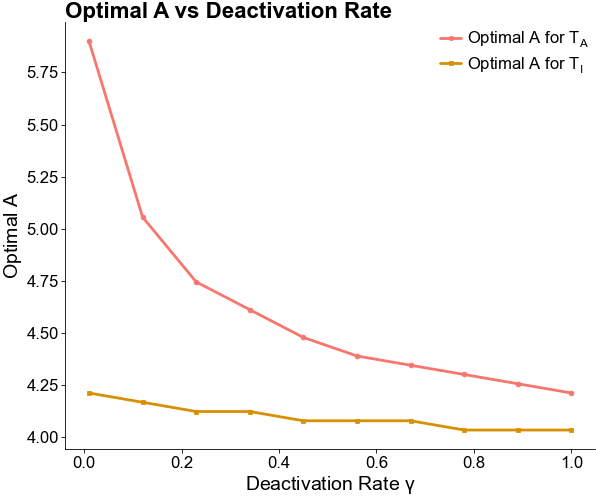

In [40]:
# investigate the optimal A for a range of deactivation rates, with fixed rn and rf

# Set range of ratios to explore
deactivation_rates = np.linspace(0.01, 1.0, 10)  # Varying the deactivation rate gamma
A_vals = np.linspace(1.5, 5.9, 100)  # A values to explore

# Initialize arrays to store results
results_A = []
results_I = []

# System parameters for the two-state model
rf = 0.2  # Fixed droplet radius
rn = 1.0
D = 1.0
ndim_ = 3

# Switching parameters for the two-state model
lam, gamma = 1.0, 0.1
activation_outside = 1  # Activation occurs outside the droplet

for gamma in deactivation_rates:
    print(f"Running simulations for deactivation rate = {gamma:.2f}...")
    T_A = np.zeros(len(A_vals))
    T_I = np.zeros(len(A_vals))
    T_single = np.zeros(len(A_vals))

    for i, A in enumerate(A_vals):
        TA_func, TI_func, out = compute_for_two_state(
            r_target=rt_,
            rf=rf,
            rn=rn,
            A=A,
            b=b_,
            D0=D,
            Dn=D,
            lam=lam,
            gamma=gamma,
            activation_outside=activation_outside,
            ndim=ndim_,
            N=300,
            tol=1e-6,
            max_nodes=20000,
        )
        T_A[i] = out["TA_rn"]
        T_I[i] = out["TI_rn"]
        T_single[i] = compute_for_sigmoidal(rt_, rf, rn, A, b_, D, D, ndim=ndim_, N=300)[0](rn)

    # Find the optimal A that minimizes T_A
    optimal_index = np.argmin(T_A)
    optimal_A = A_vals[optimal_index]
    results_A.append(optimal_A)

    # Find the optimal A that minimizes T_I
    optimal_index_I = np.argmin(T_I)
    optimal_A_I = A_vals[optimal_index_I]
    results_I.append(optimal_A_I)

# Plot the results
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(deactivation_rates, results_A, 'o-', label=r'Optimal $A$ for $T_A$')
ax.plot(deactivation_rates, results_I, 's-', label=r'Optimal $A$ for $T_I$')
ax.set_xlabel(r'Deactivation Rate $\gamma$')
ax.set_ylabel('Optimal $A$')
ax.set_title('Optimal A vs Deactivation Rate')
ax.legend()
plt.show()

In [43]:
# Save the results to a CSV file for further analysis
results_df = pd.DataFrame({
    'deactivation_rates': deactivation_rates,
    'optimal_A_TA': results_A,
    'optimal_A_TI': results_I
})
results_df.to_csv('optimal_A_vs_deactivation_rate.csv', index=False)

# Compare optimal potential to mean-field prediction
Change parameters to match those in the mean-field approximation 

In [ ]:
# System parameters for the two-state model: change to match mean-field model
rt = 0.01
rf = 0.1
rn = 0.5
D = 1.0
b = 1000.0
ndim = 3

# Switching for the two-state model (set to zero for no switching)
lam, gamma = 1.0, 0.1
activation_outside = 1  # Activation occurs outside the droplet

# Simulation parameters
dt_max = 1e-3
alpha = 0.05
n_trajectories = 1000
max_steps = 1_000_000_000

# A-values to explore 
A_values = np.linspace(1.0, 15.0, 100)

simulate = False
N_A_vals = 10
A_values_sim = A_values[::len(A_values)//N_A_vals]  # Choose 10 A-values for simulation to save time
mfpt, std = np.zeros(len(A_values_sim)), np.zeros(len(A_values_sim)) 
if simulate:
    for i, A_val in enumerate(A_values_sim):
        print(f"Running simulations for A = {A_val:.3f}...")

        results = simulate_two_state_mfpt(
            r0=rn, state0=0, # All particles start in the inactive state
            r_target=rt, rf=rf, rn=rn,
            A=A_val, b=b, D0=D, Dn=D,
            lam=lam, gamma=gamma,
            dt_max=dt_max, alpha=alpha,
            ndim=ndim, n_trajectories=n_trajectories, max_steps=max_steps)

        mfpt[i] = results['mean_fpt']
        std[i] = results['stderr_fpt']

# Calculate theoretical MFPT for each A-value
mfpt_theory_A, mfpt_theory_I = np.zeros(len(A_values)), np.zeros(len(A_values))

for i, A_val in enumerate(A_values):
    TA_func, TI_func, out = compute_for_two_state(
        r_target=rt,
        rf=rf,
        rn=rn,
        A=A_val,
        b=b,
        D0=D,
        Dn=D,
        lam=lam,
        gamma=gamma,
        activation_outside=activation_outside,
        ndim=ndim,
        N=300,
        tol=1e-6,
        max_nodes=20000,
    )
    mfpt_theory_A[i] = out["TA_rn"]  # or out["TI_rn"], depending on the initial state of interest
    mfpt_theory_I[i] = out["TI_rn"]


In [15]:
# Find the minimum MFPT and corresponding A-value
min_index_A = np.argmin(mfpt_theory_A)
min_A = A_values[min_index_A]
min_mfpt = mfpt_theory_A[min_index_A]

print(f"Minimum MFPT for initially active states occurs at A = {min_A:.3f} with MFPT = {min_mfpt:.3f}")

min_index_I = np.argmin(mfpt_theory_I)
min_A_I = A_values[min_index_I]
min_mfpt_I = mfpt_theory_I[min_index_I]

print(f"Minimum MFPT for initially inactive states occurs at A = {min_A_I:.3f} with MFPT = {min_mfpt_I:.3f}")

Minimum MFPT for initially active states occurs at A = 4.818 with MFPT = 4.180
Minimum MFPT for initially inactive states occurs at A = 4.253 with MFPT = 5.508


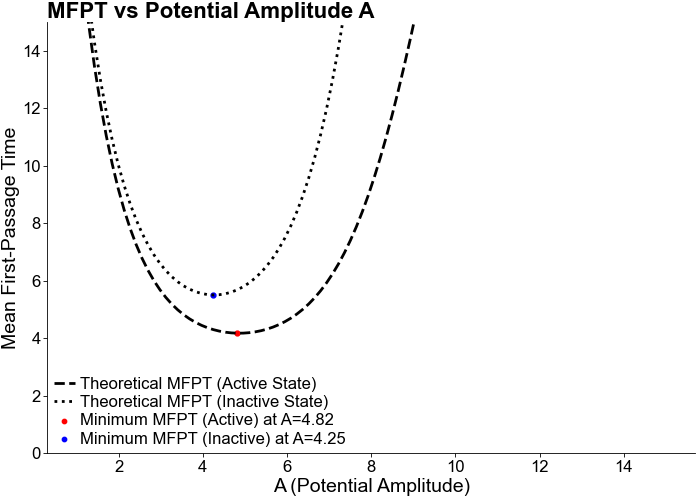

In [16]:
# Plotting the MFPT as a function of A0
plt.figure(figsize=(7, 5))
plt.plot(A_values, mfpt_theory_A, 'k--', label='Theoretical MFPT (Active State)')
plt.plot(A_values, mfpt_theory_I, 'k:', label='Theoretical MFPT (Inactive State)')

plt.scatter(min_A, min_mfpt, color='red', label=f'Minimum MFPT (Active) at A={min_A:.2f}')
plt.scatter(min_A_I, min_mfpt_I, color='blue', label=f'Minimum MFPT (Inactive) at A={min_A_I:.2f}')

if simulate: 
    plt.errorbar(A_values, mfpt, yerr=std, fmt='o', color='blue', label='Simulated MFPT')
plt.xlabel('A (Potential Amplitude)')
plt.ylabel('Mean First-Passage Time')

plt.ylim(0, 15)

plt.title('MFPT vs Potential Amplitude A')
plt.legend()
plt.show()

# Simulate occupancies for the two-state model
Compare to mean-field predictions

In [15]:
# Simulate occupancies for the two-state model and compare to mean-field predictions
occupancies = simulate_occupancies(rf, rn_, A_, b_, D0_, Dn_, 10, 2, r_min=None, r_split=None,
                         dt_max=1e-3, alpha=0.05, ndim=3, n_trajectories=200,
                         t_total=5.0, t_burn=0.5, seed=0, activation_outside=True)

In [16]:
occupancies

{'p_in_A': np.float64(0.2535226975843214),
 'p_in_N': np.float64(0.5446797439663211),
 'p_out_A': np.float64(0.12919449973223057),
 'p_out_N': np.float64(0.07260305871712641),
 'stderr': array([0.00981073, 0.01247568, 0.00539263, 0.00265333]),
 'p_A': np.float64(0.38271719731655196),
 'p_out': np.float64(0.20179755844935698),
 'alpha_in': np.float64(0.31761704097498233),
 'alpha_out': np.float64(0.640218349146445),
 'alpha_ratio': np.float64(0.49610736930367155),
 'k_minus_inferred': np.float64(1.9690995227221382),
 'delta_inferred': np.float64(1.7961390332693246)}

In [14]:
gamma

0.0